In [4]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split

from sklearn.metrics import confusion_matrix

In [8]:
SEED =42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [9]:
(X_train_full, y_train_full), (X_test_raw, y_test) = keras.datasets.mnist.load_data()

In [10]:
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.1,        # 10% for val (6000 images)
    stratify=y_train_full,
    random_state=SEED
)

In [11]:
print("Train:", X_train_raw.shape, "Val:", X_val_raw.shape, "Test:", X_test_raw.shape)

Train: (54000, 28, 28) Val: (6000, 28, 28) Test: (10000, 28, 28)


In [12]:
print(X_train_raw[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  27 125 176 176 171  55   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  27 207 252 252 252 252 245  98   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  42 245 252 241 206 121 173 244 216  3

In [13]:
print(y_train[0])

2


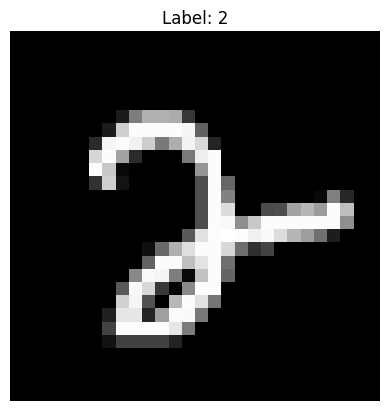

In [14]:
plt.imshow(X_train_raw[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

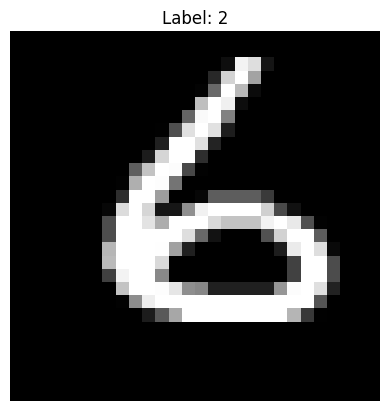

In [15]:
plt.imshow(X_train_raw[500], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

In [16]:
#normalize and add chanel dimenions

In [17]:
X_train_norm = X_train_raw.astype("float32")/255
X_val_norm = X_val_raw.astype("float32")/255
X_test_norm = X_test_raw.astype("float32")

In [18]:
#add chanel dimension
X_test_norm[0].shape

(28, 28)

In [19]:
X_train = X_train_norm.reshape(-1,28,28,1) # -1 says to figure out the number of images automatically
X_val = X_val_norm.reshape(-1,28,28,1)
X_test = X_test_norm.reshape(-1,28,28,1)

In [20]:
X_train[0].shape

(28, 28, 1)

In [24]:
model = keras.Sequential([
        keras.Input(shape=(28,28,1)),
        #convo 1
        keras.layers.Conv2D(filters=32,kernel_size=(3,3),activation="relu"),
        keras.layers.MaxPooling2D(pool_size=(2,2)),
        #convo 2
        keras.layers.Conv2D(filters=64,kernel_size=(3,3),activation = "relu"),
        keras.layers.MaxPooling2D(pool_size=(2,2)),
        #convo 3
        keras.layers.Flatten(),
        #fully connected layer
        keras.layers.Dense(units=128,activation="relu"),
        keras.layers.Dropout(rate=0.5),
        keras.layers.Dense(units=10,activation="softmax")

    ])

In [25]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
history = model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=10,batch_size=128)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 96ms/step - accuracy: 0.8994 - loss: 0.3274 - val_accuracy: 0.9793 - val_loss: 0.0780
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 93ms/step - accuracy: 0.9700 - loss: 0.1027 - val_accuracy: 0.9852 - val_loss: 0.0561
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 90ms/step - accuracy: 0.9774 - loss: 0.0764 - val_accuracy: 0.9858 - val_loss: 0.0505
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 91ms/step - accuracy: 0.9827 - loss: 0.0604 - val_accuracy: 0.9860 - val_loss: 0.0472
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 91ms/step - accuracy: 0.9844 - loss: 0.0525 - val_accuracy: 0.9878 - val_loss: 0.0437
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 91ms/step - accuracy: 0.9861 - loss: 0.0453 - val_accuracy: 0.9883 - val_loss: 0.0419
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 89ms/step - accuracy: 0.9879 - loss: 0.0399 - val_accuracy: 0.9885 - val_loss: 0.0416
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 90ms/step - accuracy: 0.9884 - loss: 0.0364 - 

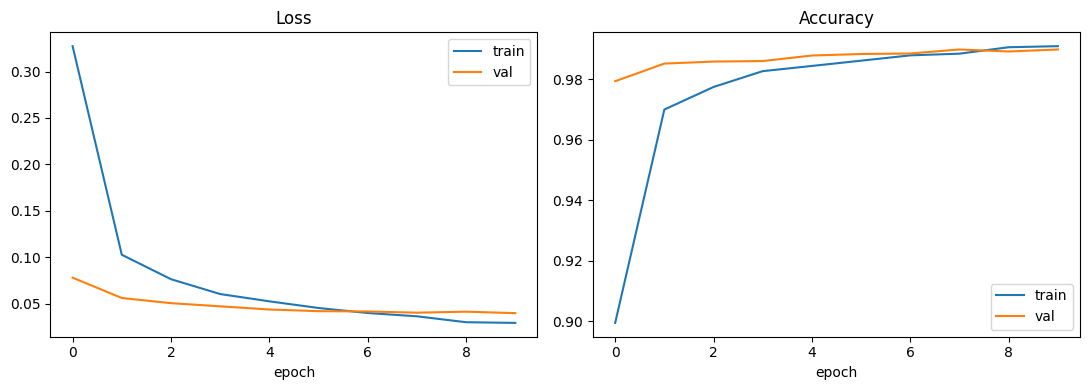

In [28]:
#leaning curves
hist = history.history

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(hist["loss"], label="train")
plt.plot(hist["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist["accuracy"], label="train")
plt.plot(hist["val_accuracy"], label="val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()

plt.tight_layout()
plt.show()

In [29]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", round(test_loss, 3))
print("Test accuracy", round(test_accuracy, 3))

Test loss: 6.284
Test accuracy 0.989


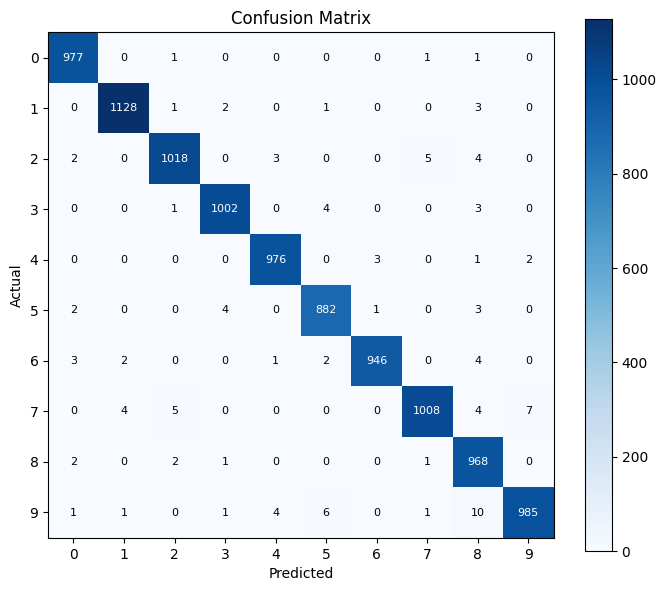

In [32]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(range(10)); plt.yticks(range(10))
for i in range(10):
    for j in range(10):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color=color)
plt.colorbar()
plt.tight_layout()
plt.show()

In [33]:
model.save("mnist_cnn_trained.keras")

In [34]:
def predict_image(image_path, model):
  """Load an image, preprocess it, display it, and return the prediction"""

  # load the image, convert it to grayscale, resize
  img = Image.open(image_path).convert("L").resize((28, 28))

  # convert to np array and anormalize to 0 - 1
  img_array = np.array(img).astype("float32") / 255

  # MNIST digits are white on black - invert it if the image is drawn in black color on white background
  if img_array.mean() > 0.5:
    img_array = 1 - img_array

  # reshape to match model input
  img_array = img_array.reshape(1, 28, 28, 1)

  # predict
  prob = model.predict(img_array, verbose=0)
  digit = np.argmax(prob)

  # Display the image with the prediction
  plt.imshow(img_array.reshape(28, 28), cmap="gray")
  plt.title(f"Predicted: {digit}")
  plt.axis("off")
  plt.show()

  return digit

In [35]:
for i in range(5):
    img = Image.fromarray(X_test_raw[i])
    img.save(f"digit_{i}_label_{y_test[i]}.png")

print("Saved 5 test images")

Saved 5 test images


In [37]:
loaded_model = keras.models.load_model("/content/mnist_cnn_trained.keras")

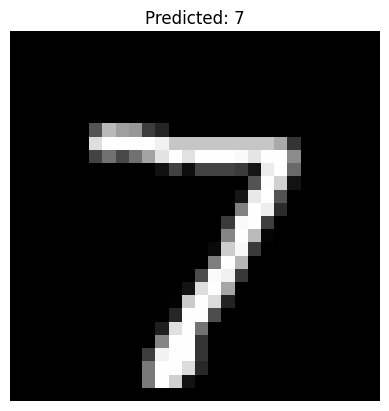

np.int64(7)

In [38]:
predict_image("/content/digit_0_label_7.png", loaded_model)